# Predictive Modeling of Student Academic Performance Using KDD Framework and Machine Learning Regression

| | |
|---|---|
| **Student Name** | Kalyani Eknath Borkar |
| **PRN** | 23070521036 |
| **Programme** | B.Tech CSE (AI & ML), Sem VII, Section A |
| **Course** | Predictive Analytics (T3366) – CA3 Project |
| **Institute** | Symbiosis Institute of Technology |

**Target variable:** Student Performance Index (continuous, 0–100)
**Predictors:** study hours/day, previous exam score, attendance (%), practice papers solved, sleep hours/day

**KDD pipeline followed:** Selection → Preprocessing → Transformation → Data Mining (Modeling) → Interpretation/Evaluation

## 0. Environment Setup

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("Libraries loaded successfully.")

Libraries loaded successfully.


## Stage 1 – Selection (Synthetic Data Generation)

Since the project must run standalone, 1,000 realistic student records are simulated. The target is generated from a
documented *data-generating process*: positive contributions from study hours, previous score, attendance and practice
papers, a **non-linear sleep effect** (performance peaks near ~7.5 h and drops for too little/too much sleep) and Gaussian noise.

To make preprocessing meaningful, ~2% missing values and a few recording errors (extreme outliers) are deliberately injected.

In [ ]:
N = 1000
rng = np.random.default_rng(RANDOM_STATE)

study_hours    = np.clip(rng.normal(4.5, 1.8, N), 0.5, 12)          # hours / day
previous_score = np.clip(rng.normal(65, 14, N), 15, 100)           # previous exam (0-100)
attendance     = np.clip(rng.normal(82, 9, N), 40, 100)            # %
papers_solved  = np.clip(rng.poisson(6, N), 0, 25).astype(float)   # practice papers
sleep_hours    = np.clip(rng.normal(7, 1.1, N), 3.5, 10)           # hours / day

# Data-generating process for the Student Performance Index
performance = (
    8
    + 0.55 * previous_score
    + 2.2  * study_hours
    + 0.17 * attendance
    + 0.60 * papers_solved
    - 1.5  * (sleep_hours - 7.5) ** 2        # non-linear sleep effect
    + rng.normal(0, 4.0, N)                   # irreducible noise
)
performance = np.clip(performance, 0, 100)

df = pd.DataFrame({
    "study_hours":     study_hours,
    "previous_score":  previous_score,
    "attendance":      attendance,
    "papers_solved":   papers_solved,
    "sleep_hours":     sleep_hours,
    "performance_index": performance,
})

# ---- Inject realistic data-quality problems ----
# (a) ~2% missing values in predictors
for col in ["study_hours", "previous_score", "attendance", "papers_solved", "sleep_hours"]:
    idx = rng.choice(N, size=int(0.02 * N), replace=False)
    df.loc[idx, col] = np.nan
# (b) a handful of recording errors (outliers)
df.loc[rng.choice(N, 6, replace=False), "study_hours"] = rng.uniform(16, 22, 6)
df.loc[rng.choice(N, 5, replace=False), "papers_solved"] = rng.uniform(40, 60, 5)
df.loc[rng.choice(N, 4, replace=False), "sleep_hours"]  = rng.uniform(0.5, 1.5, 4)

print("Shape:", df.shape)
df.head()

Shape: (1000, 6)


,study_hours,previous_score,attendance,papers_solved,sleep_hours,performance_index
0,5.0485,64.1700,77.9324,10.0000,7.7092,68.5878
1,2.6280,54.7900,76.0071,12.0000,5.6477,65.5321
2,5.8508,59.1974,85.9061,2.0000,8.8693,64.1066
3,6.1930,73.8747,84.2667,8.0000,6.1166,81.2365
4,0.9881,65.0419,69.3569,7.0000,8.9113,63.3058


In [ ]:
print("Descriptive statistics (raw data):")
df.describe().T

Descriptive statistics (raw data):


,count,mean,std,min,25%,50%,75%,max
study_hours,980.0000,4.5643,2.1216,0.5000,3.2779,4.5238,5.6286,21.2214
previous_score,980.0000,63.7996,14.1809,22.3331,54.7764,64.2297,73.4529,100.0000
attendance,980.0000,82.1795,8.9126,54.4260,76.0863,82.2916,88.3733,100.0000
papers_solved,980.0000,6.1189,3.8455,0.0000,4.0000,6.0000,7.0000,55.4456
sleep_hours,980.0000,6.9249,1.1556,0.6039,6.2132,6.9306,7.6833,10.0000
performance_index,"1,000.0000",68.1599,10.2223,31.2339,61.7638,68.1507,74.7552,100.0000


## Stage 2 – Preprocessing (Cleaning)

Steps: (1) missing-value audit, (2) duplicate check, (3) median imputation (robust to outliers), (4) IQR fencing.

**IQR fence rule:** $\text{Lower} = Q_1 - 1.5\,\text{IQR}$, $\text{Upper} = Q_3 + 1.5\,\text{IQR}$.
Values outside are treated as anomalies and **winsorized (capped)** to the fence rather than deleted, so all 1,000 records are preserved.

In [ ]:
# ---- 2.1 Missing-value audit ----
missing = df.isnull().sum().to_frame("missing_count")
missing["missing_%"] = 100 * missing["missing_count"] / len(df)
print("Missing values per column:")
display(missing)

# ---- 2.2 Duplicate check ----
print("Duplicate rows:", df.duplicated().sum())

# ---- 2.3 Median imputation (median is robust to the outliers we are about to treat) ----
feature_cols = ["study_hours", "previous_score", "attendance", "papers_solved", "sleep_hours"]
target_col   = "performance_index"
df[feature_cols] = df[feature_cols].fillna(df[feature_cols].median())
print("\nMissing values after imputation:", int(df.isnull().sum().sum()))

Missing values per column:


,missing_count,missing_%
study_hours,20,2.0000
previous_score,20,2.0000
attendance,20,2.0000
papers_solved,20,2.0000
sleep_hours,20,2.0000
performance_index,0,0.0000


Duplicate rows: 0

Missing values after imputation: 0


IQR outlier report (before treatment):


,feature,lower_fence,upper_fence,n_outliers
0,study_hours,-0.1163,9.0422,11
1,previous_score,27.4997,100.4410,6
2,attendance,58.4578,105.9577,4
3,papers_solved,-0.5000,11.5000,26
4,sleep_hours,4.0705,9.8171,13


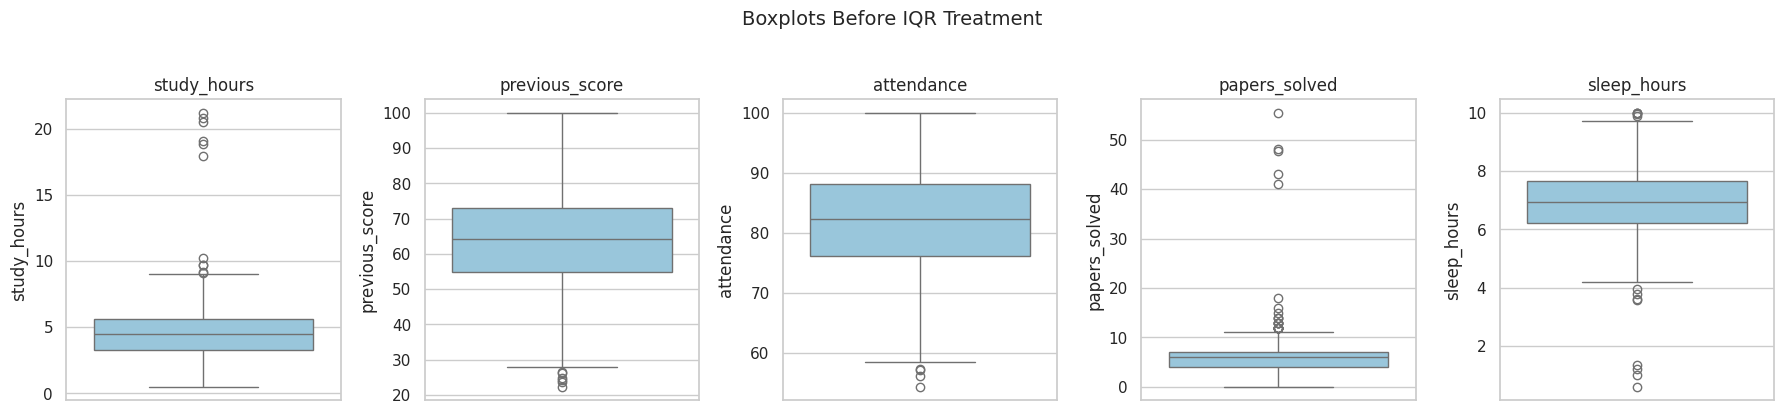

In [ ]:
# ---- 2.4 Outlier detection using IQR fencing ----
def iqr_fences(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for col in feature_cols:
    lo, hi = iqr_fences(df[col])
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append([col, lo, hi, n_out])
outlier_report = pd.DataFrame(rows, columns=["feature", "lower_fence", "upper_fence", "n_outliers"])
print("IQR outlier report (before treatment):")
display(outlier_report)

# Boxplots BEFORE treatment
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, feature_cols):
    sns.boxplot(y=df[col], ax=ax, color="#8ecae6")
    ax.set_title(col)
plt.suptitle("Boxplots Before IQR Treatment", y=1.03, fontsize=14)
plt.tight_layout(); plt.show()

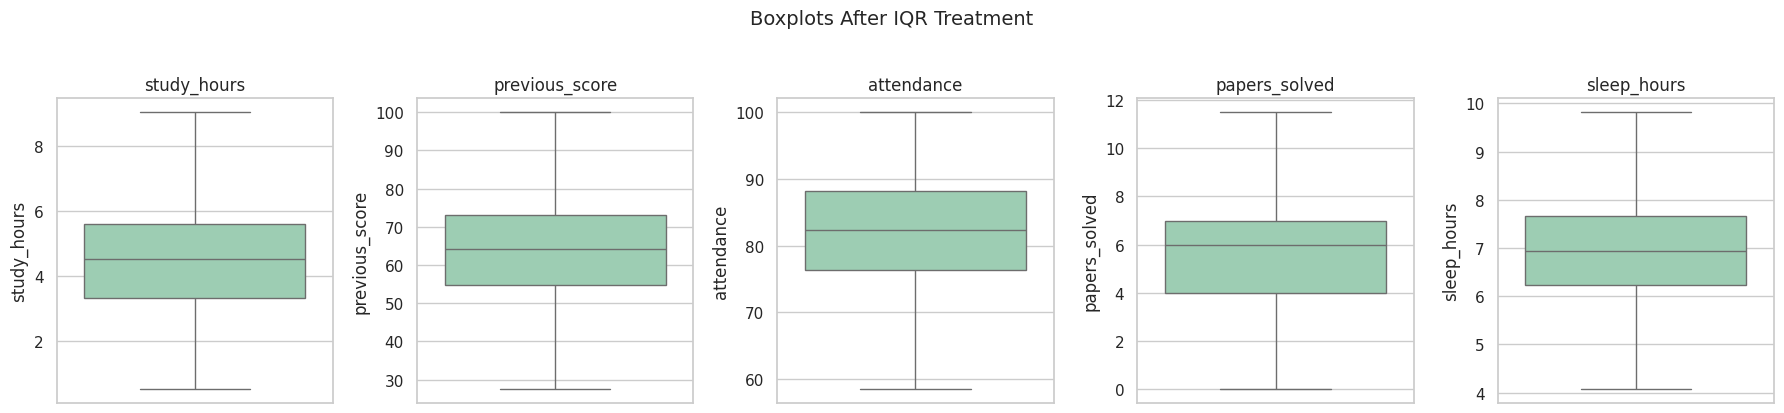

Clean dataset shape: (1000, 6)


,count,mean,std,min,25%,50%,75%,max
study_hours,"1,000.0000",4.4965,1.7627,0.5000,3.3182,4.5238,5.6078,9.0422
previous_score,"1,000.0000",63.8256,13.9909,27.4997,54.8527,64.2297,73.0880,100.0000
attendance,"1,000.0000",82.1904,8.7982,58.4578,76.2703,82.2916,88.1452,100.0000
papers_solved,"1,000.0000",5.9040,2.3617,0.0000,4.0000,6.0000,7.0000,11.5000
sleep_hours,"1,000.0000",6.9378,1.0906,4.0705,6.2255,6.9306,7.6621,9.8171
performance_index,"1,000.0000",68.1599,10.2223,31.2339,61.7638,68.1507,74.7552,100.0000


In [ ]:
# ---- 2.5 Treat anomalies: cap (winsorize) at IQR fences ----
for col in feature_cols:
    lo, hi = iqr_fences(df[col])
    df[col] = df[col].clip(lower=lo, upper=hi)

# Boxplots AFTER treatment
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, feature_cols):
    sns.boxplot(y=df[col], ax=ax, color="#95d5b2")
    ax.set_title(col)
plt.suptitle("Boxplots After IQR Treatment", y=1.03, fontsize=14)
plt.tight_layout(); plt.show()

print("Clean dataset shape:", df.shape)
df.describe().T

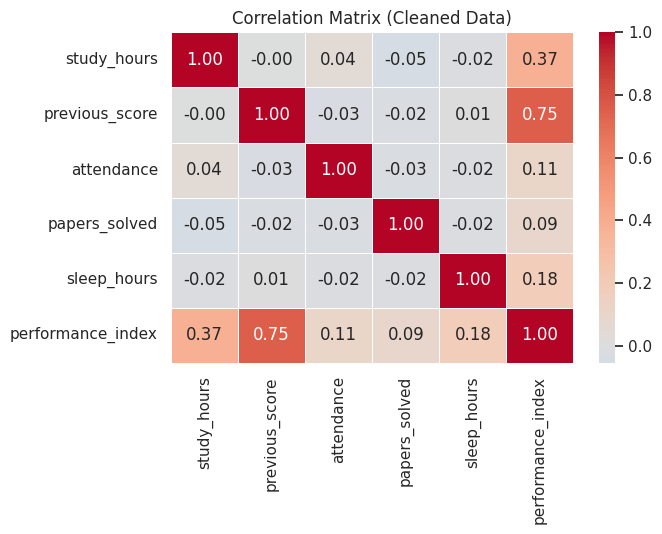

In [ ]:
# ---- Exploratory view: correlation heatmap ----
plt.figure(figsize=(7, 5.5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Correlation Matrix (Cleaned Data)")
plt.tight_layout(); plt.show()

## Stage 3 – Transformation

1. **80/20 train–test split** (`random_state=42`) – the test set stays unseen until final evaluation.
2. **Z-score standardization:** $z = \dfrac{x-\mu}{\sigma}$, with $\mu,\sigma$ learned from the **training set only** (prevents data leakage).

In [ ]:
X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# ------------------------------------------------------------------
# WHY SCALING MATTERS (mandatory for distance-based methods such as k-NN):
# Distance-based learners (e.g. k-NN, Euclidean d = sqrt(sum (x_i - x'_i)^2))
# are dominated by large-range features if data is unscaled. Our features live
# on very different scales: previous_score / attendance range ~40-100, whereas
# study_hours ~0-12 and sleep_hours ~3-10. Z-scoring puts every feature at
# mean 0 and std 1 so each contributes proportionally.
# For the two models used here: scaling makes OLS coefficients directly
# comparable (effect per 1 std), and is harmless for Random Forest because
# trees are scale-invariant.
# ------------------------------------------------------------------
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)  # fit ONLY on train
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),      columns=feature_cols, index=X_test.index)   # reuse train mu/sigma

print("\nScaled training set (mean ~ 0, std ~ 1):")
display(X_train_scaled.describe().loc[["mean", "std"]])

Train: (800, 5), Test: (200, 5)

Scaled training set (mean ~ 0, std ~ 1):


,study_hours,previous_score,attendance,papers_solved,sleep_hours
mean,-0.0000,-0.0000,0.0000,0.0000,0.0000
std,1.0006,1.0006,1.0006,1.0006,1.0006


## Stage 4 – Predictive Modeling (Data Mining)

Two syllabus algorithms are trained and compared (a simple baseline vs. an ensemble):

| # | Model | Key setting |
|---|---|---|
| 1 | Multiple Linear Regression (OLS) | Baseline |
| 2 | Random Forest Regressor | 100 trees, bagging (bootstrap) |

**5-fold cross-validation** is run on the training data. Each model is wrapped in a `Pipeline` with a `StandardScaler`,
so scaling is re-fitted inside every fold (no leakage from the validation fold).

In [ ]:
def make_pipeline(estimator):
    return Pipeline([("scaler", StandardScaler()), ("model", estimator)])

models = {
    "Linear Regression (OLS)": make_pipeline(LinearRegression()),
    "Random Forest (100 trees)": make_pipeline(RandomForestRegressor(
        n_estimators=100, bootstrap=True, random_state=RANDOM_STATE, n_jobs=-1)),
}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, pipe in models.items():
    r2_cv   = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2")
    rmse_cv = -cross_val_score(pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
    cv_rows.append([name, r2_cv.mean(), r2_cv.std(), rmse_cv.mean(), rmse_cv.std()])

cv_table = pd.DataFrame(cv_rows, columns=["Model", "CV R2 (mean)", "CV R2 (std)", "CV RMSE (mean)", "CV RMSE (std)"])
print("5-Fold Cross-Validation Results (training data only):")
display(cv_table.set_index("Model"))

5-Fold Cross-Validation Results (training data only):


,CV R2 (mean),CV R2 (std),CV RMSE (mean),CV RMSE (std)
Model,,,,
Linear Regression (OLS),0.7566,0.0356,4.9202,0.3288
Random Forest (100 trees),0.7424,0.0207,5.0697,0.1338


In [ ]:
# Fit both models on the full training set (scaled features, as produced in Stage 3)
fitted = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)      # pipeline scaler is fitted on X_train only
    fitted[name] = pipe
print("Both models trained on the training set.")

# Interpretability: OLS coefficients on standardized features + Random Forest importances
ols = fitted["Linear Regression (OLS)"].named_steps["model"]
rf  = fitted["Random Forest (100 trees)"].named_steps["model"]
interp = pd.DataFrame({
    "OLS coef (per 1 std)": ols.coef_,
    "RF importance": rf.feature_importances_
}, index=feature_cols).sort_values("RF importance", ascending=False)
print("\nFeature influence:")
display(interp)

Both models trained on the training set.

Feature influence:


,OLS coef (per 1 std),RF importance
previous_score,7.6069,0.6045
study_hours,3.9477,0.1982
sleep_hours,1.9857,0.1115
attendance,1.1229,0.0516
papers_solved,1.5970,0.0342


## Stage 5 – Evaluation & Interpretation

Metrics on the **held-out test set**:

- $\text{MAE}=\frac{1}{n}\sum|y_i-\hat y_i|$
- $\text{RMSE}=\sqrt{\frac{1}{n}\sum(y_i-\hat y_i)^2}$
- $R^2 = 1-\dfrac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$

In [ ]:
results = []
predictions = {}
for name, pipe in fitted.items():
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "MAE":  mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2":   r2_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1
results_df.index.name = "Rank"

print("=" * 66)
print("MODEL COMPARISON ON TEST SET (20% hold-out)")
print("=" * 66)
display(results_df.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.4f}"})
        .highlight_max(subset=["R2"], color="#b7e4c7")
        .highlight_min(subset=["MAE", "RMSE"], color="#b7e4c7"))

best_model_name = results_df.loc[1, "Model"]
print(f"\nWinning model: {best_model_name}  (R2 = {results_df.loc[1, 'R2']:.4f})")

MODEL COMPARISON ON TEST SET (20% hold-out)


,Model,MAE,RMSE,R2
Rank,,,,
1,Random Forest (100 trees),3.967,4.968,0.7853
2,Linear Regression (OLS),3.818,4.988,0.7835



Winning model: Random Forest (100 trees)  (R2 = 0.7853)


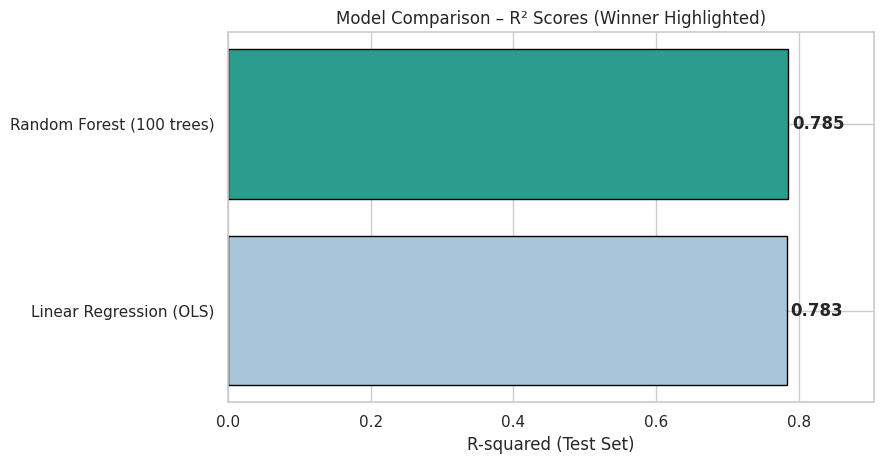

In [ ]:
# ---- (a) Model Comparison Bar Chart (R2) ----
order = results_df.sort_values("R2", ascending=True)
colors = ["#2a9d8f" if m == best_model_name else "#a8c5da" for m in order["Model"]]

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(order["Model"], order["R2"], color=colors, edgecolor="black")
for bar, val in zip(bars, order["R2"]):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2, f"{val:.3f}", va="center", fontweight="bold")
ax.set_xlim(0, min(1.0, order["R2"].max() + 0.12))
ax.set_xlabel("R-squared (Test Set)")
ax.set_title("Model Comparison – R² Scores (Winner Highlighted)")
plt.tight_layout(); plt.show()

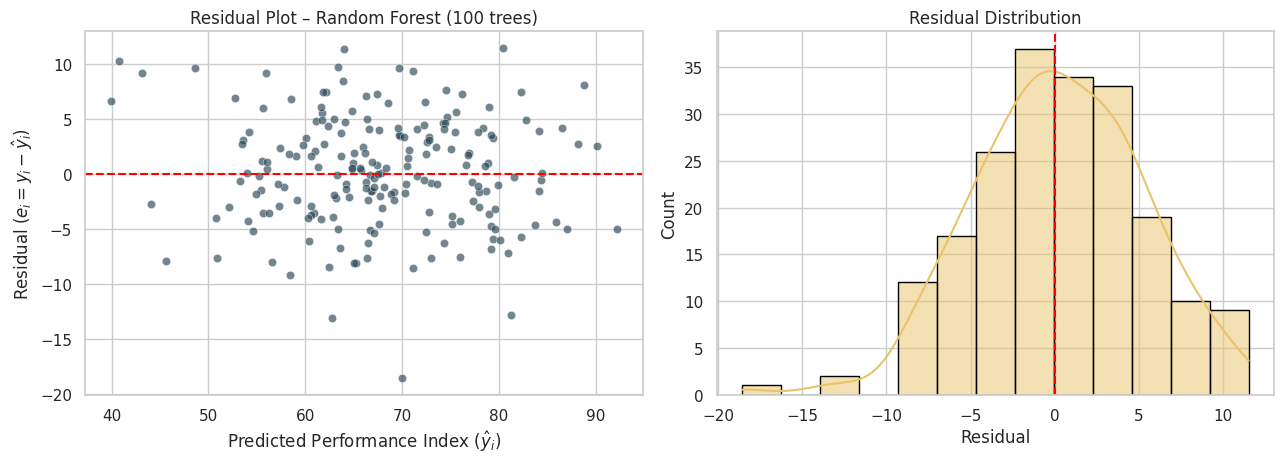

Mean residual              : 0.2207  (should be ~0)
Residual std dev           : 4.9631
corr(|residual|, y_hat)    : -0.0507  (|value| near 0 => no funnel shape / homoscedastic)


In [ ]:
# ---- (b) Residual Scatter Plot for the winning model: e_i = y_i - y_hat_i ----
y_pred_best = predictions[best_model_name]
residuals = y_test.values - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Residuals vs fitted: a random horizontal band around 0 => constant variance (homoscedasticity)
axes[0].scatter(y_pred_best, residuals, alpha=0.65, color="#264653", edgecolor="white", linewidth=.4)
axes[0].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[0].set_xlabel(r"Predicted Performance Index ($\hat{y}_i$)")
axes[0].set_ylabel(r"Residual ($e_i = y_i - \hat{y}_i$)")
axes[0].set_title(f"Residual Plot – {best_model_name}")

# Residual distribution
sns.histplot(residuals, kde=True, ax=axes[1], color="#e9c46a", edgecolor="black")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Residual"); axes[1].set_title("Residual Distribution")
plt.tight_layout(); plt.show()

# Quick numerical homoscedasticity check: correlation between |residual| and prediction
corr_abs = np.corrcoef(np.abs(residuals), y_pred_best)[0, 1]
print(f"Mean residual              : {residuals.mean():.4f}  (should be ~0)")
print(f"Residual std dev           : {residuals.std():.4f}")
print(f"corr(|residual|, y_hat)    : {corr_abs:.4f}  (|value| near 0 => no funnel shape / homoscedastic)")

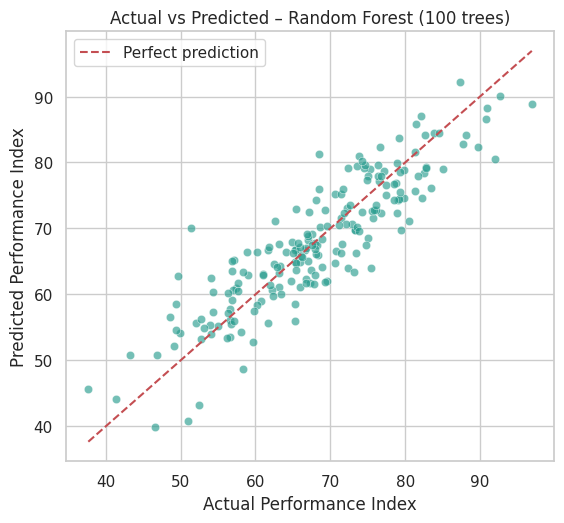

In [ ]:
# ---- Supplementary: Actual vs Predicted for the winning model ----
plt.figure(figsize=(5.8, 5.4))
plt.scatter(y_test, y_pred_best, alpha=0.65, color="#2a9d8f", edgecolor="white", linewidth=.4)
lims = [min(y_test.min(), y_pred_best.min()), max(y_test.max(), y_pred_best.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Performance Index"); plt.ylabel("Predicted Performance Index")
plt.title(f"Actual vs Predicted – {best_model_name}")
plt.legend(); plt.tight_layout(); plt.show()

## Conclusion & Interpretation

- **Pipeline:** all five KDD stages were implemented – selection (1,000 simulated records), preprocessing (median imputation, IQR winsorizing),
  transformation (80/20 split, Z-score scaling fitted on train only), modeling (OLS and Random Forest with 5-fold CV)
  and evaluation (MAE, RMSE, R²).
- **Model choice:** the comparison table and R² bar chart above identify the best generalizing model on unseen data.
  Compare it with the CV table – a small gap between CV and test scores indicates good generalization and no data leakage.
- **Residual diagnostics:** residuals centred near zero with no funnel pattern support the homoscedasticity assumption;
  a visible curve would indicate unmodelled non-linearity (such as the sleep effect).
- **Drivers of performance:** the feature-influence table shows which habits (e.g. previous score, study hours) contribute most.
- **Limitations:** the data is synthetic, so real-world results may differ; hyper-parameter tuning (e.g. `GridSearchCV` for the number of trees and tree depth)
  and real institutional data are natural next steps.

*Prepared by Kalyani Eknath Borkar (PRN 23070521036)